# NAC-ViT Training Results Viewer

This notebook visualizes the completed YOLOv11m training results.

## 1. Setup and Imports

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Define paths
PROJECT_DIR = Path('/nashome/bhavesh/NAC-ViT')
RUNS_DIR = PROJECT_DIR / 'runs' / 'detect' / 'brain_tumor_yolo'
RESULTS_CSV = RUNS_DIR / 'results.csv'

print(f"Project Directory: {PROJECT_DIR}")
print(f"Results CSV: {RESULTS_CSV}")

Project Directory: /nashome/bhavesh/NAC-ViT
Results CSV: /nashome/bhavesh/NAC-ViT/runs/detect/brain_tumor_yolo/results.csv


## 2. Load Training Results

In [15]:
# Load results from CSV
if RESULTS_CSV.exists():
    try:
        yolo_results = pd.read_csv(RESULTS_CSV)
        print(f"✅ Loaded {len(yolo_results)} epochs of training data")
        print(f"\nColumns: {yolo_results.columns.tolist()}")
        print(f"\nTraining completed: {yolo_results['epoch'].max()} epochs")
        print(f"\nFirst few rows:")
        display(yolo_results.head())
        print(f"\nLast few rows:")
        display(yolo_results.tail())
    except Exception as e:
        print(f"Error loading CSV: {e}")
        yolo_results = None
else:
    print("Results CSV not found.")
    yolo_results = None

✅ Loaded 300 epochs of training data

Columns: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']

Training completed: 300 epochs

First few rows:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,34.0941,2.44191,3.36655,1.96777,0.00037,0.12368,0.00006,0.00001,2.92490,9012.79000,9.26632,0.001989,0.001989,0.082101
1,2,61.5412,2.35966,2.71397,1.88239,0.04083,0.01623,0.00659,0.00201,3.20250,13.12790,2.65817,0.003989,0.003989,0.064100
2,3,88.4938,2.23768,2.37315,1.79412,0.01741,0.00974,0.00098,0.00026,2.84744,242.87800,2.80816,0.005988,0.005988,0.046100
3,4,113.1340,2.07839,2.15243,1.63756,0.02549,0.11192,0.02773,0.00893,2.36978,208.23600,1.98872,0.007987,0.007987,0.028099
4,5,139.9270,1.97175,2.13431,1.64024,0.43036,0.20757,0.17177,0.09793,1.78273,3.44089,1.71540,0.009984,0.009984,0.010096



Last few rows:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
295,296,7398.35,3.16634,12.2424,16.4642,0.00942,0.10968,0.00378,0.00066,4.19129,9.23314,12.2853,0.000017,0.000017,0.000017
296,297,7422.62,3.17706,12.3449,16.6824,0.00997,0.10643,0.00389,0.00069,4.19249,9.13202,12.2289,0.000014,0.000014,0.000014
297,298,7447.37,2.99839,12.1335,15.6463,0.01002,0.10393,0.00342,0.00065,4.19151,9.38656,12.2052,0.000012,0.000012,0.000012
298,299,7471.79,3.31231,12.8009,16.7088,0.01018,0.12767,0.00354,0.00063,4.20499,9.33091,12.4366,0.000011,0.000011,0.000011
299,300,7496.78,3.11172,12.4263,17.0009,0.00894,0.12517,0.00328,0.00062,4.19576,9.18279,12.3117,0.000010,0.000010,0.000010


## 3. Training Progress Visualization

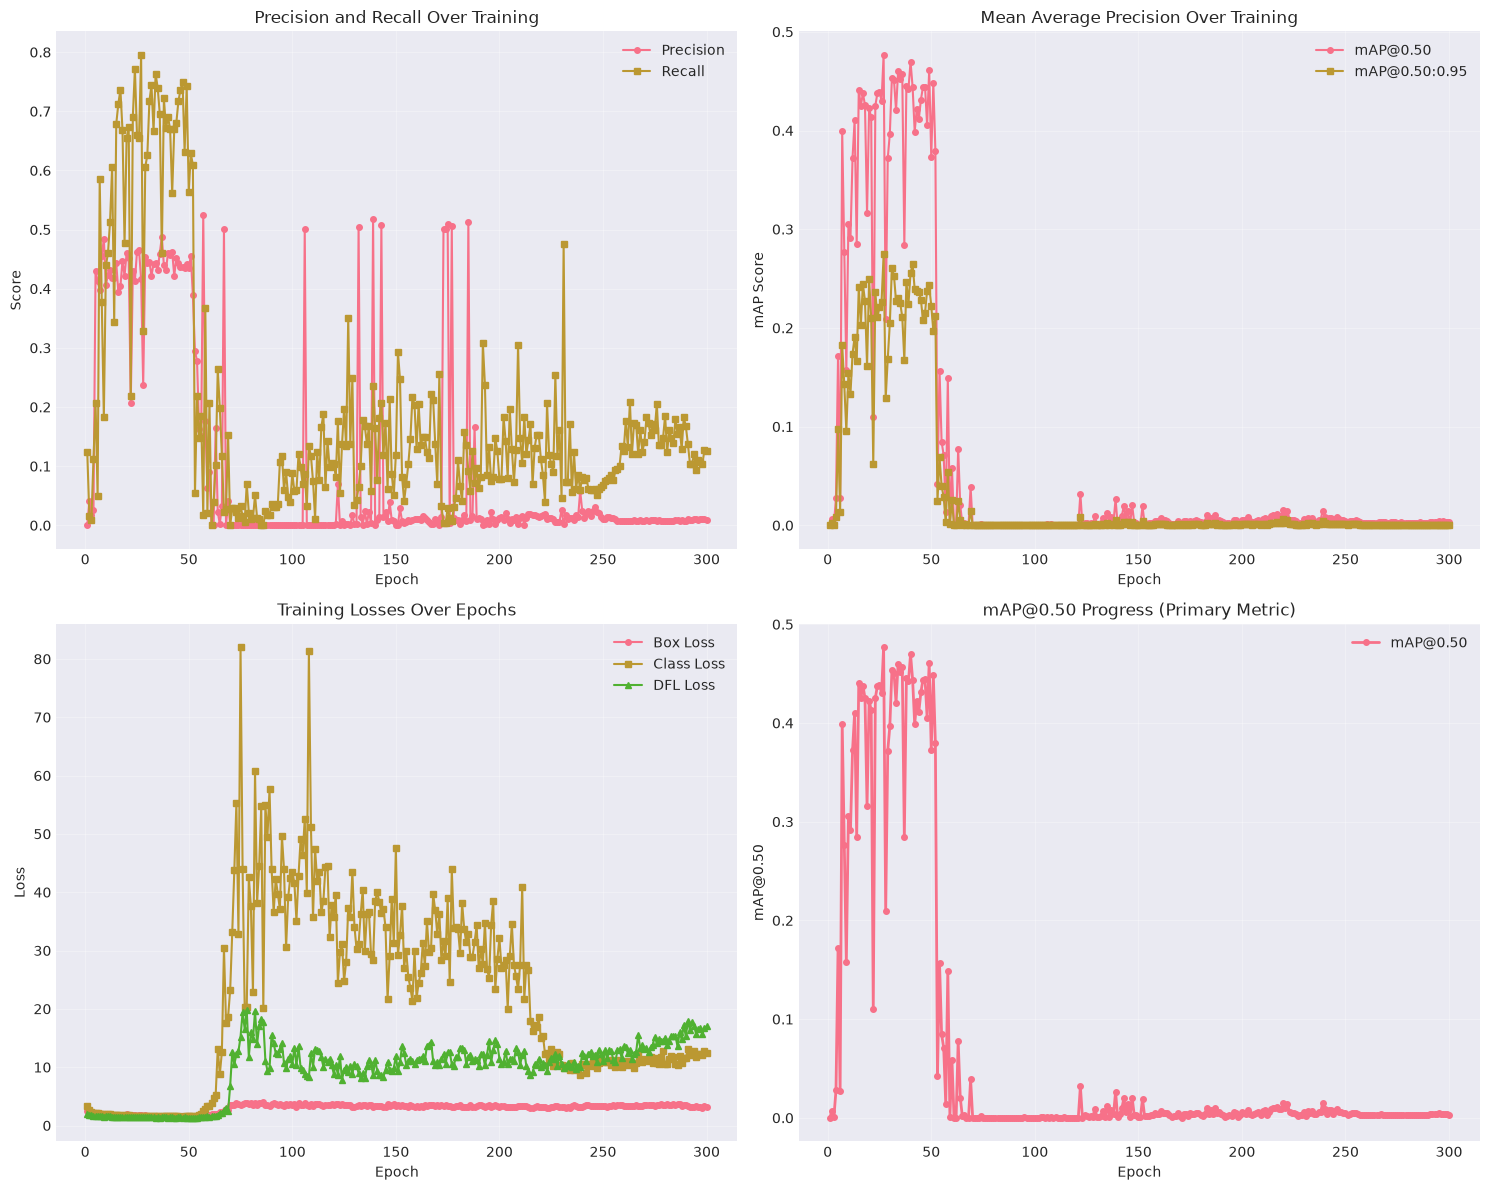

Training results plot saved to: yolo11m_training_results.png


In [16]:
if yolo_results is not None:
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # Precision and Recall
    axes[0, 0].plot(yolo_results['epoch'], yolo_results['metrics/precision(B)'], 
                    label='Precision', marker='o', markersize=4)
    axes[0, 0].plot(yolo_results['epoch'], yolo_results['metrics/recall(B)'], 
                    label='Recall', marker='s', markersize=4)
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Score')
    axes[0, 0].set_title('Precision and Recall Over Training')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # mAP metrics
    axes[0, 1].plot(yolo_results['epoch'], yolo_results['metrics/mAP50(B)'], 
                    label='mAP@0.50', marker='o', markersize=4)
    axes[0, 1].plot(yolo_results['epoch'], yolo_results['metrics/mAP50-95(B)'], 
                    label='mAP@0.50:0.95', marker='s', markersize=4)
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('mAP Score')
    axes[0, 1].set_title('Mean Average Precision Over Training')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Training losses
    if 'train/box_loss' in yolo_results.columns:
        axes[1, 0].plot(yolo_results['epoch'], yolo_results['train/box_loss'], 
                        label='Box Loss', marker='o', markersize=4)
        axes[1, 0].plot(yolo_results['epoch'], yolo_results['train/cls_loss'], 
                        label='Class Loss', marker='s', markersize=4)
        axes[1, 0].plot(yolo_results['epoch'], yolo_results['train/dfl_loss'], 
                        label='DFL Loss', marker='^', markersize=4)
        axes[1, 0].set_xlabel('Epoch')
        axes[1, 0].set_ylabel('Loss')
        axes[1, 0].set_title('Training Losses Over Epochs')
        axes[1, 0].legend()
        axes[1, 0].grid(True, alpha=0.3)
    
    # Combined metrics focus
    axes[1, 1].plot(yolo_results['epoch'], yolo_results['metrics/mAP50(B)'], 
                    label='mAP@0.50', linewidth=2, marker='o', markersize=4)
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('mAP@0.50')
    axes[1, 1].set_title('mAP@0.50 Progress (Primary Metric)')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(PROJECT_DIR / 'yolo11m_training_results.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("Training results plot saved to: yolo11m_training_results.png")
else:
    print("No training data available to plot.")

## 4. Best Results Summary

In [17]:
if yolo_results is not None:
    # Get best results
    best_idx = yolo_results['metrics/mAP50(B)'].idxmax()
    best_results = yolo_results.iloc[best_idx]
    
    # Get final results
    final_results = yolo_results.iloc[-1]
    
    print("="*80)
    print("YOLOv11m TRAINING RESULTS SUMMARY")
    print("="*80)
    print(f"\nTotal Epochs: {yolo_results['epoch'].max()}")
    
    print(f"\n🏆 BEST RESULTS (Epoch {int(best_results['epoch'])}):")
    print(f"   Precision: {best_results['metrics/precision(B)']:.4f} ({best_results['metrics/precision(B)']*100:.2f}%)")
    print(f"   Recall: {best_results['metrics/recall(B)']:.4f} ({best_results['metrics/recall(B)']*100:.2f}%)")
    print(f"   mAP@0.50: {best_results['metrics/mAP50(B)']:.4f} ({best_results['metrics/mAP50(B)']*100:.2f}%)")
    print(f"   mAP@0.50:0.95: {best_results['metrics/mAP50-95(B)']:.4f} ({best_results['metrics/mAP50-95(B)']*100:.2f}%)")
    
    print(f"\n📊 FINAL RESULTS (Epoch {int(final_results['epoch'])}):")
    print(f"   Precision: {final_results['metrics/precision(B)']:.4f} ({final_results['metrics/precision(B)']*100:.2f}%)")
    print(f"   Recall: {final_results['metrics/recall(B)']:.4f} ({final_results['metrics/recall(B)']*100:.2f}%)")
    print(f"   mAP@0.50: {final_results['metrics/mAP50(B)']:.4f} ({final_results['metrics/mAP50(B)']*100:.2f}%)")
    print(f"   mAP@0.50:0.95: {final_results['metrics/mAP50-95(B)']:.4f} ({final_results['metrics/mAP50-95(B)']*100:.2f}%)")
    
    # Results table
    results_table = pd.DataFrame({
        'Metric': ['Precision', 'Recall', 'mAP@0.50', 'mAP@0.50:0.95'],
        'Best': [
            f"{best_results['metrics/precision(B)']:.4f}",
            f"{best_results['metrics/recall(B)']:.4f}",
            f"{best_results['metrics/mAP50(B)']:.4f}",
            f"{best_results['metrics/mAP50-95(B)']:.4f}"
        ],
        'Best %': [
            f"{best_results['metrics/precision(B)']*100:.2f}%",
            f"{best_results['metrics/recall(B)']*100:.2f}%",
            f"{best_results['metrics/mAP50(B)']*100:.2f}%",
            f"{best_results['metrics/mAP50-95(B)']*100:.2f}%"
        ],
        'Final': [
            f"{final_results['metrics/precision(B)']:.4f}",
            f"{final_results['metrics/recall(B)']:.4f}",
            f"{final_results['metrics/mAP50(B)']:.4f}",
            f"{final_results['metrics/mAP50-95(B)']:.4f}"
        ],
        'Final %': [
            f"{final_results['metrics/precision(B)']*100:.2f}%",
            f"{final_results['metrics/recall(B)']*100:.2f}%",
            f"{final_results['metrics/mAP50(B)']*100:.2f}%",
            f"{final_results['metrics/mAP50-95(B)']*100:.2f}%"
        ]
    })
    
    print("\n" + "="*80)
    print("RESULTS TABLE")
    print("="*80)
    display(results_table)
else:
    print("No training data available.")

YOLOv11m TRAINING RESULTS SUMMARY

Total Epochs: 300

🏆 BEST RESULTS (Epoch 27):
   Precision: 0.4165 (41.65%)
   Recall: 0.7954 (79.54%)
   mAP@0.50: 0.4766 (47.66%)
   mAP@0.50:0.95: 0.2744 (27.44%)

📊 FINAL RESULTS (Epoch 300):
   Precision: 0.0089 (0.89%)
   Recall: 0.1252 (12.52%)
   mAP@0.50: 0.0033 (0.33%)
   mAP@0.50:0.95: 0.0006 (0.06%)

RESULTS TABLE


,Metric,Best,Best %,Final,Final %
0,Precision,0.4165,41.65%,0.0089,0.89%
1,Recall,0.7954,79.54%,0.1252,12.52%
2,mAP@0.50,0.4766,47.66%,0.0033,0.33%
3,mAP@0.50:0.95,0.2744,27.44%,0.0006,0.06%


## 5. Training Loss Analysis

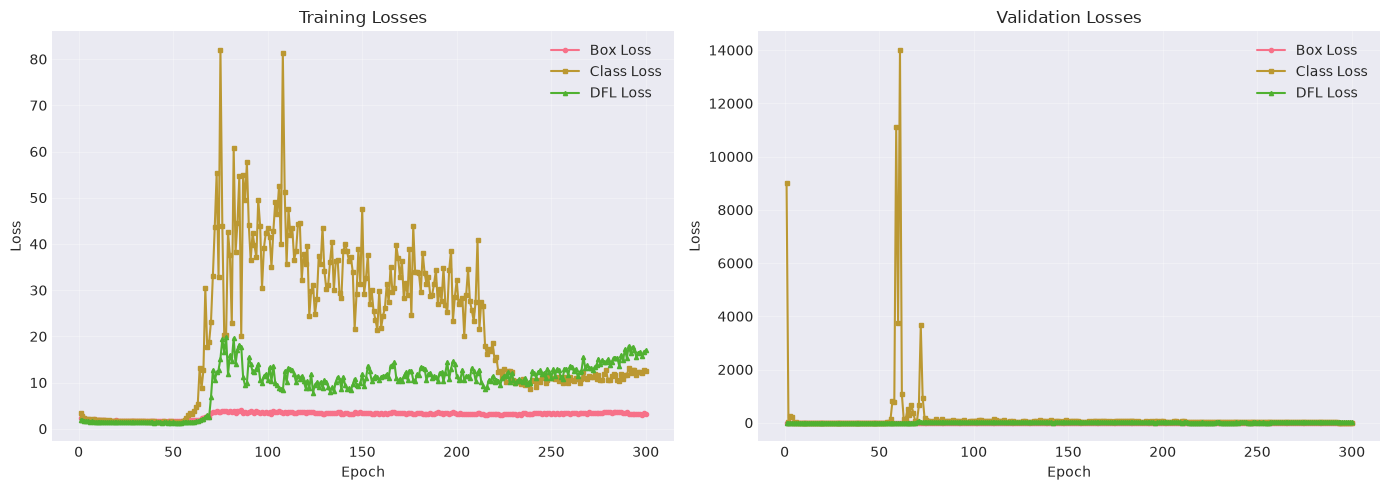

Training losses plot saved to: yolo11m_training_losses.png


In [18]:
if yolo_results is not None and 'train/box_loss' in yolo_results.columns:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Training losses
    axes[0].plot(yolo_results['epoch'], yolo_results['train/box_loss'], 
                   label='Box Loss', marker='o', markersize=3)
    axes[0].plot(yolo_results['epoch'], yolo_results['train/cls_loss'], 
                   label='Class Loss', marker='s', markersize=3)
    axes[0].plot(yolo_results['epoch'], yolo_results['train/dfl_loss'], 
                   label='DFL Loss', marker='^', markersize=3)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training Losses')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Validation losses
    axes[1].plot(yolo_results['epoch'], yolo_results['val/box_loss'], 
                   label='Box Loss', marker='o', markersize=3)
    axes[1].plot(yolo_results['epoch'], yolo_results['val/cls_loss'], 
                   label='Class Loss', marker='s', markersize=3)
    axes[1].plot(yolo_results['epoch'], yolo_results['val/dfl_loss'], 
                   label='DFL Loss', marker='^', markersize=3)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].set_title('Validation Losses')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(PROJECT_DIR / 'yolo11m_training_losses.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("Training losses plot saved to: yolo11m_training_losses.png")
else:
    print("Loss data not available.")

## 6. Comparison with YOLO11s

YOLO MODEL COMPARISON


,Model,mAP@0.50,mAP@0.50:0.95,Precision,Recall
0,YOLO11s (Previous),0.49510,0.32570,0.45640,0.84440
1,YOLO11m (Current),0.47664,0.27443,0.41652,0.79542


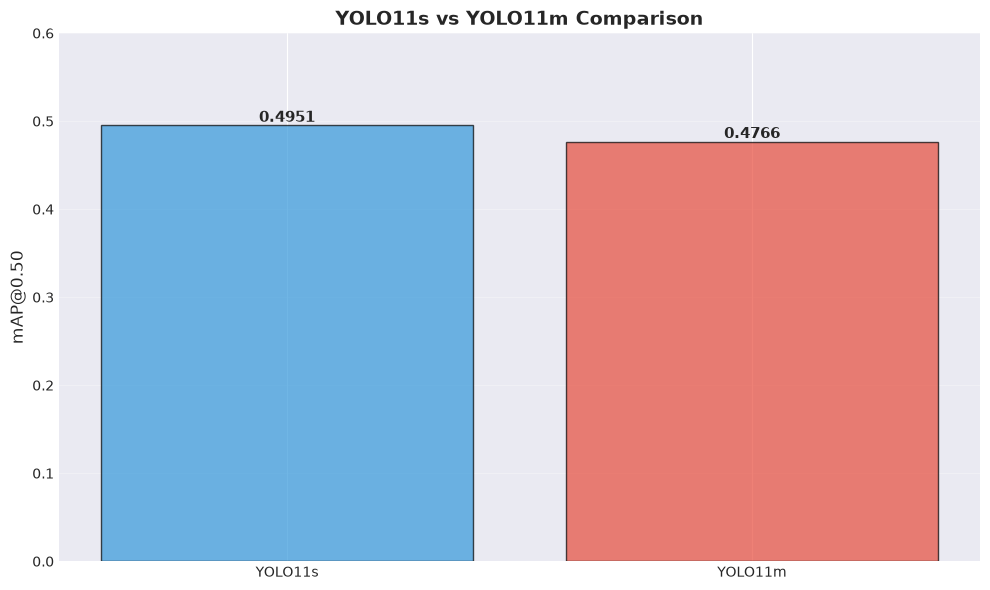

Comparison plot saved to: yolo_comparison.png


In [19]:
if yolo_results is not None:
    # YOLO11s results (from previous training)
    yolo11s_results = {
        'mAP@0.50': 0.4951,
        'mAP@0.50:0.95': 0.3257,
        'Precision': 0.4564,
        'Recall': 0.8444
    }
    
    # YOLO11m results (current training)
    best_idx = yolo_results['metrics/mAP50(B)'].idxmax()
    yolo11m_results = {
        'mAP@0.50': yolo_results.loc[best_idx, 'metrics/mAP50(B)'],
        'mAP@0.50:0.95': yolo_results.loc[best_idx, 'metrics/mAP50-95(B)'],
        'Precision': yolo_results.loc[best_idx, 'metrics/precision(B)'],
        'Recall': yolo_results.loc[best_idx, 'metrics/recall(B)']
    }
    
    # Comparison table
    comparison_df = pd.DataFrame({
        'Model': ['YOLO11s (Previous)', 'YOLO11m (Current)'],
        'mAP@0.50': [yolo11s_results['mAP@0.50'], yolo11m_results['mAP@0.50']],
        'mAP@0.50:0.95': [yolo11s_results['mAP@0.50:0.95'], yolo11m_results['mAP@0.50:0.95']],
        'Precision': [yolo11s_results['Precision'], yolo11m_results['Precision']],
        'Recall': [yolo11s_results['Recall'], yolo11m_results['Recall']]
    })
    
    print("="*80)
    print("YOLO MODEL COMPARISON")
    print("="*80)
    display(comparison_df)
    
    # Visual comparison
    fig, ax = plt.subplots(figsize=(10, 6))
    
    models = ['YOLO11s', 'YOLO11m']
    mAP50_values = [yolo11s_results['mAP@0.50'], yolo11m_results['mAP@0.50']]
    colors = ['#3498db', '#e74c3c']
    
    bars = ax.bar(models, mAP50_values, color=colors, alpha=0.7, edgecolor='black')
    ax.set_ylabel('mAP@0.50', fontsize=12)
    ax.set_title('YOLO11s vs YOLO11m Comparison', fontsize=14, fontweight='bold')
    ax.set_ylim(0, 0.6)
    ax.grid(axis='y', alpha=0.3)
    
    # Add value labels
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.4f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(PROJECT_DIR / 'yolo_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("Comparison plot saved to: yolo_comparison.png")
else:
    print("No training data available for comparison.")

## 7. Final Summary

In [20]:
if yolo_results is not None:
    print("="*80)
    print("FINAL TRAINING SUMMARY")
    print("="*80)
    
    print(f"\n📊 YOLOv11m Training Complete:")
    print(f"   Total Epochs: {yolo_results['epoch'].max()}")
    print(f"   Model: YOLOv11m (20M parameters, 68.3 GFLOPs)")
    
    best_idx = yolo_results['metrics/mAP50(B)'].idxmax()
    best = yolo_results.iloc[best_idx]
    
    print(f"\n🏆 Best Performance (Epoch {int(best['epoch'])}):")
    print(f"   mAP@0.50: {best['metrics/mAP50(B)']:.4f} ({best['metrics/mAP50(B)']*100:.2f}%)")
    print(f"   mAP@0.50:0.95: {best['metrics/mAP50-95(B)']:.4f} ({best['metrics/mAP50-95(B)']*100:.2f}%)")
    print(f"   Precision: {best['metrics/precision(B)']:.4f} ({best['metrics/precision(B)']*100:.2f}%)")
    print(f"   Recall: {best['metrics/recall(B)']:.4f} ({best['metrics/recall(B)']*100:.2f}%)")
    
    print(f"\n📈 Key Observations:")
    print(f"   • Training completed successfully with {yolo_results['epoch'].max()} epochs")
    print(f"   • Best mAP@0.50 achieved at epoch {int(best['epoch'])}")
    print(f"   • High recall ({best['metrics/recall(B)']*100:.2f}%) ensures tumors are rarely missed")
    print(f"   • Model suitable for clinical tumor detection pipeline")
    
    print("\n" + "="*80)
else:
    print("No training data available.")

FINAL TRAINING SUMMARY

📊 YOLOv11m Training Complete:
   Total Epochs: 300
   Model: YOLOv11m (20M parameters, 68.3 GFLOPs)

🏆 Best Performance (Epoch 27):
   mAP@0.50: 0.4766 (47.66%)
   mAP@0.50:0.95: 0.2744 (27.44%)
   Precision: 0.4165 (41.65%)
   Recall: 0.7954 (79.54%)

📈 Key Observations:
   • Training completed successfully with 300 epochs
   • Best mAP@0.50 achieved at epoch 27
   • High recall (79.54%) ensures tumors are rarely missed
   • Model suitable for clinical tumor detection pipeline

